In [1]:
import pandas as pd

In [2]:
from matplotlib_venn import venn3
import matplotlib.pyplot as plt



def plot_venn_diagram(venn_numbers):
    fig, ax = plt.subplots(figsize=(8,8))

    v = venn3(
        subsets=(
            venn_numbers["Model"].item(),
            venn_numbers["Dataset"].item(),
            venn_numbers["Model, Dataset"].item(),
            venn_numbers["Evaluation"].item(),
            venn_numbers["Model, Evaluation"].item(),
            venn_numbers["Dataset, Evaluation"].item(),
            venn_numbers["Model, Dataset, Evaluation"].item()
        ),
        set_labels=('Model', 'Dataset', 'Evaluation')
    )

    # -----------------------------
    # Set label font sizes
    # -----------------------------
    for text in v.set_labels:
        text.set_fontsize(16)

    # -----------------------------
    # Subset number font sizes
    # -----------------------------
    for text in v.subset_labels:
        if text:
            text.set_fontsize(14)

    # -----------------------------
    # Region colors
    # IDs:
    # 100, 010, 110, 001, 101, 011, 111
    # -----------------------------
    v.get_patch_by_id('100').set_color('red')
    v.get_patch_by_id('010').set_color('green')
    v.get_patch_by_id('001').set_color('blue')

    # Optional:
    v.get_patch_by_id('111').set_color('purple')

    # -----------------------------
    # Transparency
    # -----------------------------
    for region in ['100', '010', '110', '001', '101', '011', '111']:
        patch = v.get_patch_by_id(region)
        if patch:
            patch.set_alpha(0.6)

    # -----------------------------
    # Borders
    # -----------------------------
    for region in ['100', '010', '110', '001', '101', '011', '111']:
        patch = v.get_patch_by_id(region)
        if patch:
            patch.set_edgecolor('black')
            patch.set_linewidth(1.5)

    # plt.show()

    plt.savefig(
        "data/results/venn.png",
        dpi=300,
        bbox_inches='tight'
    )

# SCREENING PROCESS

In [13]:
path = r"data\src\conflated_database___2026_03_31__11_14_35.xlsx"

title_df = pd.read_excel(path, sheet_name="TitleReading")
abstract_df = pd.read_excel(path, sheet_name="AbstractReading")
excluded_df = pd.read_excel(path, sheet_name="TextReading_Excluded")
included_df = pd.read_excel(path, sheet_name="TextReading_Included")

excluded_df = excluded_df[excluded_df["Exclusion reason"].notna()].reset_index(drop=True)
included_df = included_df[included_df["topic"].notna()].reset_index(drop=True)
included_df.Year = included_df.Year.astype(int)

In [14]:
screened = title_df.is_included.shape[0]
print(f"screened: {screened}")

included_titles = title_df.is_included.value_counts()["yes"].item()
excluded_titles = screened - included_titles
print(f"excluded -- title reading: {excluded_titles}")

excluded_abstracts = abstract_df[abstract_df.topic.isin(["Irrelevant", "Duplicate"])].shape[0]
included_abstracts = abstract_df.shape[0] - excluded_abstracts
print(f"excluded -- abstract reading: {excluded_abstracts}")
print(f"sought for retrieval (included): {included_abstracts}")
print(f"check: {excluded_titles + excluded_abstracts + included_abstracts} =? {screened}")
print()

not_retrieved = excluded_df[excluded_df["Exclusion reason"] == "Not retrievable"].shape[0]
retrieved_excluded = excluded_df[excluded_df["Exclusion reason"] != "Not retrievable"].shape[0]
retrieved_included = included_df.shape[0]
retrieved = retrieved_included + retrieved_excluded 

print(f"not retrieved: {not_retrieved}")
print(f"retrieved: {retrieved}")
print()

print(f"retrieved excluded: {retrieved_excluded}")
print(f"retrieved included: {retrieved_included}")
print(f"check: {included_abstracts} =? {not_retrieved + retrieved_excluded + retrieved_included}")
print()

print(excluded_df["Exclusion reason"].value_counts())


screened: 693
excluded -- title reading: 534
excluded -- abstract reading: 56
sought for retrieval (included): 103
check: 693 =? 693

not retrieved: 2
retrieved: 101

retrieved excluded: 29
retrieved included: 72
check: 103 =? 103

Exclusion reason
Data               12
Irrelevant          7
Visual report       6
Model               3
Not retrievable     2
Duplicate           1
Name: count, dtype: int64


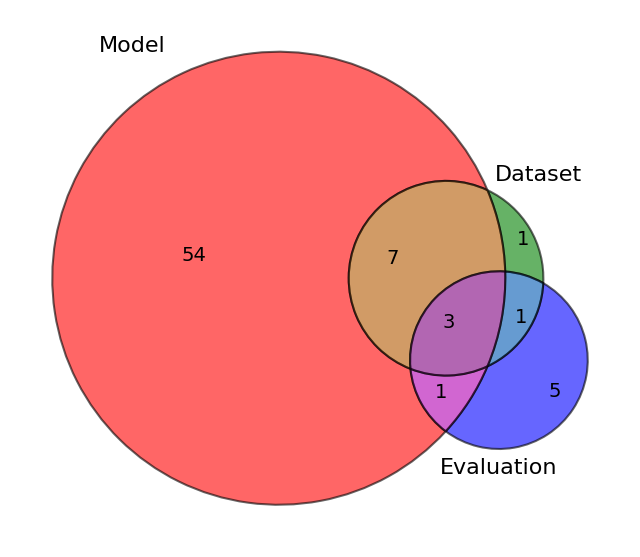

In [ ]:
# venn diagram: paper topic

venn_numbers = pd.DataFrame(included_df.topic.value_counts()).T
plot_venn_diagram(venn_numbers)

In [ ]:
# papers per year

counts = included_df.groupby(['Year', 'Source']).size().unstack(fill_value=0)
counts = counts.sort_index()
counts

Source,Scopus,arXiv
Year,,
2019,1,0
2020,4,0
2021,1,0
2022,7,0
2023,8,4
2024,17,4
2025,24,2


<Axes: xlabel='Year', ylabel='# papers'>

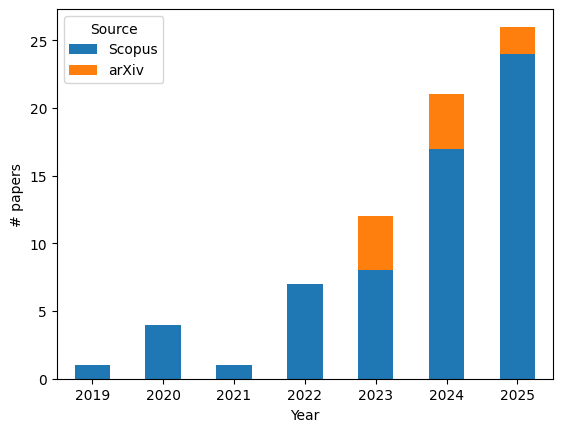

In [18]:
counts.plot(
    kind='bar',
    stacked=True,
    rot=0,
    ylabel="# papers"
)